In [1]:
# Instalar optuna
!pip install -q optuna

# Librerias
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import folium
import branca
import numpy as np

import random
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit
import optuna

In [2]:
# Buscar un CSV local; si no está disponible, usar la fuente original online.
raiz = Path.cwd()
if raiz.name == 'notebooks':
    raiz = raiz.parent
ruta_csv = raiz / 'data' / 'processed' / 'produccion_limpia_filtrada.csv'
print('CSV local disponible:', ruta_csv.is_file())

CSV local disponible: False


In [3]:
URL_CSV = 'https://github.com/molijoaquin-DA/vaca-muerta-produccion/raw/refs/heads/main/data/processed/produccion_limpia_filtrada.csv'
fuente = ruta_csv if ruta_csv.is_file() else URL_CSV
df_filtrado = pd.read_csv(fuente, encoding='utf-8-sig', low_memory=False)
print('Fuente:', fuente)
print(f'Filas: {len(df_filtrado):,} | Columnas: {df_filtrado.shape[1]}')
display(df_filtrado.head())

Fuente: https://github.com/molijoaquin-DA/vaca-muerta-produccion/raw/refs/heads/main/data/processed/produccion_limpia_filtrada.csv
Filas: 30,325 | Columnas: 24


,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,iny_agua,tef,tipoextraccion,tipoestado,...,coordenaday,clasificacion,subclasificacion,tef_valido,prod_pet_dia,prod_gas_dia,prod_agua_dia,fecha,fecha_inicio_observada,edad_pozo_meses
0,2021,1,161685,3924.21,618.56,934.95,0.0,31.00,Surgencia Natural,Extracción Efectiva,...,-38.298358,EXPLOTACION,DESARROLLO,True,126.587419,19.953548,30.159677,2021-01-01,2020-02-01,11.0
1,2018,1,158425,0.00,7131.91,1404.08,0.0,28.56,Surgencia Natural,Extracción Efectiva,...,-38.000978,EXPLOTACION,DESARROLLO,True,0.000000,249.716737,49.162465,2018-01-01,2017-09-01,4.0
2,2021,1,157108,0.00,0.00,0.00,0.0,0.00,Surgencia Natural,Parado Transitoriamente,...,-37.972551,EXPLOTACION,DESARROLLO,False,NaN,NaN,NaN,2021-01-01,2016-09-01,52.0
3,2018,1,156710,1508.78,208.70,111.64,0.0,31.00,Surgencia Natural,Extracción Efectiva,...,-38.330794,EXPLOTACION,DESARROLLO,True,48.670323,6.732258,3.601290,2018-01-01,2016-05-01,20.0
4,2018,1,156469,20.96,180.02,0.00,0.0,30.00,Surgencia Natural,Extracción Efectiva,...,-38.017366,EXPLOTACION,DESARROLLO,True,0.698667,6.000667,0.000000,2018-01-01,2016-03-01,22.0


In [4]:
print("Duplicados:", df_filtrado.duplicated(["idpozo", "anio", "mes"]).sum())

Duplicados: 0


## Modelos

### Predicción de extracción futura

“Con la información disponible de un pozo hasta este mes, ¿cuál será su producción diaria de petróleo, gas y agua el mes siguiente?"

Para ver la producción futura el modelo tendrá en cuenta qué pasó los meses anteriores, es por ello que se deben crear columnas nuevas referidas al valor de los meses pasados pero sólo nos interesa saber el valor pasado de algunas columnas. Además, para las variables a predecir se tiene que tener qué pasó el mes siguiente.

“Estimar las tasas diarias de producción del próximo mes para pozos con historial suficiente, usando información disponible al momento de emitir el pronóstico”.

In [5]:
# Columnas nuevas a crear (pasado)
columnas_lag = [
    "prod_pet_dia",
    "prod_gas_dia",
    "prod_agua_dia",
    "tipoextraccion",
]

periodos = [1, 2, 3]

# Columnas nuevas a crear (futuras)
targets_futuros = ["prod_pet_dia", "prod_gas_dia", "prod_agua_dia"]

# Se necesita para corroborar que el lag y el lead tomen el mes correcto
df_filtrado["fecha"] = pd.to_datetime(
    dict(year=df_filtrado["anio"], month=df_filtrado["mes"], day=1)
)

df = df_filtrado.sort_values(["idpozo", "fecha"]).copy()

# Creación de variables pasadas (Lags)
for col in columnas_lag:
    for lag in periodos:
        df[f"{col}_lag_{lag}"] = (
            df.groupby("idpozo")[col].shift(lag)
        )

        fecha_lag = df.groupby("idpozo")["fecha"].shift(lag)

        diferencia_meses_lag = (
            (df["fecha"].dt.year - fecha_lag.dt.year) * 12
            + df["fecha"].dt.month
            - fecha_lag.dt.month
        )

        df.loc[
            diferencia_meses_lag != lag,
            f"{col}_lag_{lag}"
        ] = float("nan")

# Creación de variables objetivo del mes siguiente (Lead 1)
for col in targets_futuros:
    df[f"{col}_lead_1"] = (
        df.groupby("idpozo")[col].shift(-1)
    )

    fecha_lead = df.groupby("idpozo")["fecha"].shift(-1)

    # La diferencia para el mes siguiente debe ser exactamente de -1 mes utilizando la misma lógica matemática
    diferencia_meses_lead = (
        (df["fecha"].dt.year - fecha_lead.dt.year) * 12
        + df["fecha"].dt.month
        - fecha_lead.dt.month
    )

    df.loc[
        diferencia_meses_lead != -1,
        f"{col}_lead_1"
    ] = float("nan")

df.head()

,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,iny_agua,tef,tipoextraccion,tipoestado,...,prod_gas_dia_lag_3,prod_agua_dia_lag_1,prod_agua_dia_lag_2,prod_agua_dia_lag_3,tipoextraccion_lag_1,tipoextraccion_lag_2,tipoextraccion_lag_3,prod_pet_dia_lead_1,prod_gas_dia_lead_1,prod_agua_dia_lead_1
24923,2013,10,145735,627.35,14.18,506.18,0.0,10.00,Surgencia Natural,Extracción Efectiva,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41.667333,1.680667,16.842333
26454,2013,11,145735,1250.02,50.42,505.27,0.0,30.00,Surgencia Natural,Extracción Efectiva,...,NaN,50.618000,NaN,NaN,Surgencia Natural,NaN,NaN,22.402903,0.963226,11.352581
29314,2013,12,145735,694.49,29.86,351.93,0.0,31.00,Surgencia Natural,Extracción Efectiva,...,NaN,16.842333,50.618000,NaN,Surgencia Natural,Surgencia Natural,NaN,8.995161,0.357097,4.603226
1199,2014,1,145735,278.85,11.07,142.70,0.0,31.00,Surgencia Natural,Extracción Efectiva,...,1.418000,11.352581,16.842333,50.618000,Surgencia Natural,Surgencia Natural,Surgencia Natural,2.829149,1.824279,3.139378
3127,2014,2,145735,75.51,48.69,83.79,0.0,26.69,Surgencia Natural,Extracción Efectiva,...,1.680667,4.603226,11.352581,16.842333,Surgencia Natural,Surgencia Natural,Surgencia Natural,1.129032,2.211935,4.488710


In [6]:
# Selección de variables independientes
columnas_base = ['anio', 'mes', 'profundidad',
    'tipoextraccion', 'tipopozo', 'areayacimiento', 'edad_pozo_meses', "prod_pet_dia", "prod_gas_dia", "prod_agua_dia"
]

# Consideramos todos las columnas referidas al pasado
for i in periodos:
    columnas_base.append(f"prod_pet_dia_lag_{i}")
    columnas_base.append(f"prod_gas_dia_lag_{i}")
    columnas_base.append(f"prod_agua_dia_lag_{i}")
    columnas_base.append(f"tipoextraccion_lag_{i}")

# Los targets futuros a predecir
targets = ['prod_pet_dia_lead_1', 'prod_gas_dia_lead_1', 'prod_agua_dia_lead_1']

df_limpio = df[columnas_base + targets].dropna()

categoricas = df_limpio.select_dtypes(
    include=["object", "category"]
).columns.tolist()

binarias = [
    col for col in categoricas
    if df_limpio[col].nunique() == 2
]

multicategoricas = [
    col for col in categoricas
    if df_limpio[col].nunique() > 2
]

# Utilizamos dummies para pasar las columnas categóricas a números mediante creación de columnas de 0 y 1

# Para una categoría binaria con tener una columna binaria que diga 0 y 1 es suficiente
df_dummies = pd.get_dummies(
    df_limpio,
    columns=binarias,
    drop_first=True,
    dtype=int
)

# Para el caso de las categorías no binarias entonces es necesario crear tantas columnas (que tengan 0 y 1) como categorías haya.
# El caso de random tree se puede mantener todas esas columnas, no hay problema de multicolinealidad que afecte al modelo
df_dummies = pd.get_dummies(
    df_dummies,
    columns=multicategoricas,
    drop_first=False,
    dtype=int
)

# Sacar las targets de dummies
df_dummies = df_dummies.drop(columns=targets)

# Como la columna mes es cíclica (12 valores) entonces para que el modelo interprete que el mes 12 está cerca
# del mes 1 se tienen que crear columnas usando el seno y el coseno
df_dummies["mes_sin"] = np.sin(2 * np.pi * df_dummies["mes"] / 12)
df_dummies["mes_cos"] = np.cos(2 * np.pi * df_dummies["mes"] / 12)

# Se elimina la columna mes
df_dummies.drop(columns=["mes"], inplace=True)

df_dummies.head()

,anio,profundidad,edad_pozo_meses,prod_pet_dia,prod_gas_dia,prod_agua_dia,prod_pet_dia_lag_1,prod_gas_dia_lag_1,prod_agua_dia_lag_1,prod_pet_dia_lag_2,...,tipoextraccion_Surgencia Natural,tipopozo_Petrolífero,tipoextraccion_lag_1_Surgencia Natural,tipoextraccion_lag_2_Surgencia Natural,tipoextraccion_lag_3_Surgencia Natural,areayacimiento_EL OREJANO,areayacimiento_LA AMARGA CHICA,areayacimiento_LOMA CAMPANA,mes_sin,mes_cos
1199,2014,3170.0,3.0,8.995161,0.357097,4.603226,22.402903,0.963226,11.352581,41.667333,...,1,1,1,1,1,0,0,1,0.500000,8.660254e-01
3127,2014,3170.0,4.0,2.829149,1.824279,3.139378,8.995161,0.357097,4.603226,22.402903,...,1,1,1,1,1,0,0,1,0.866025,5.000000e-01
4916,2014,3170.0,5.0,1.129032,2.211935,4.488710,2.829149,1.824279,3.139378,8.995161,...,1,1,1,1,1,0,0,1,1.000000,6.123234e-17
7580,2014,3170.0,6.0,5.039298,2.577544,4.459649,1.129032,2.211935,4.488710,2.829149,...,1,1,1,1,1,0,0,1,0.866025,-5.000000e-01
10564,2014,3170.0,7.0,48.504662,1.537296,9.590909,5.039298,2.577544,4.459649,1.129032,...,1,1,1,1,1,0,0,1,0.500000,-8.660254e-01


--- Cobertura Temporal de los Conjuntos ---
Conjunto de Desarrollo (Dev):  2014-01 hasta 2024-01 (121 meses)
Conjunto de Test Final (20%): 2024-02 hasta 2026-08 (31 meses)



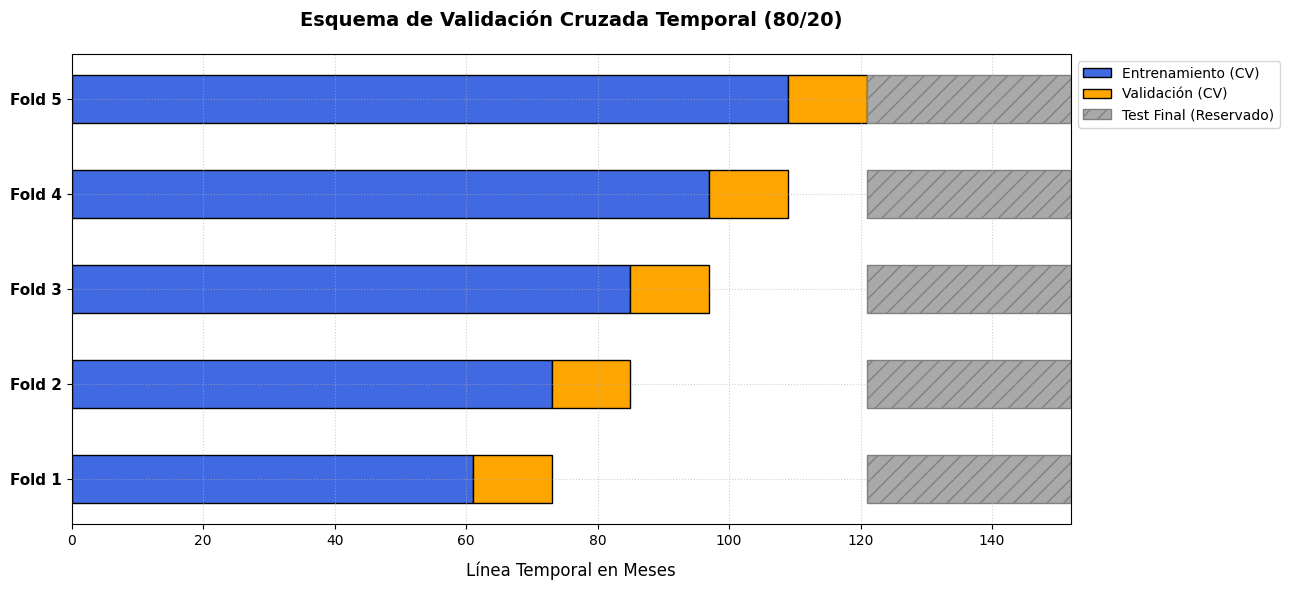

In [7]:
# Variables predictoras y objetivos
X_multi = df_dummies
y_multi = df_limpio[targets]

# Ordenar los períodos únicos cronológicamente
periodos_unicos = (
    df_limpio[['anio', 'mes']]
    .drop_duplicates()
    .sort_values(['anio', 'mes'])
    .reset_index(drop=True)
)

# Separación temporal: 80 % desarrollo, 20 % test final
split_idx = int(len(periodos_unicos) * 0.8)

periodos_dev = periodos_unicos.iloc[:split_idx].copy()
periodos_test = periodos_unicos.iloc[split_idx:].copy()

# Determinar fechas límites de forma explícita
fecha_min_dev = f"{periodos_dev.iloc[0]['anio']}-{str(periodos_dev.iloc[0]['mes']).zfill(2)}"
fecha_max_dev = f"{periodos_dev.iloc[-1]['anio']}-{str(periodos_dev.iloc[-1]['mes']).zfill(2)}"
fecha_min_test = f"{periodos_test.iloc[0]['anio']}-{str(periodos_test.iloc[0]['mes']).zfill(2)}"
fecha_max_test = f"{periodos_test.iloc[-1]['anio']}-{str(periodos_test.iloc[-1]['mes']).zfill(2)}"

print("--- Cobertura Temporal de los Conjuntos ---")
print(f"Conjunto de Desarrollo (Dev):  {fecha_min_dev} hasta {fecha_max_dev} ({len(periodos_dev)} meses)")
print(f"Conjunto de Test Final (20%): {fecha_min_test} hasta {fecha_max_test} ({len(periodos_test)} meses)\n")

# Máscaras para las filas del dataset completo
periodos_filas = pd.MultiIndex.from_frame(
    df_limpio[['anio', 'mes']]
)

idx_dev = pd.MultiIndex.from_frame(
    periodos_dev[['anio', 'mes']]
)

idx_test = pd.MultiIndex.from_frame(
    periodos_test[['anio', 'mes']]
)

mask_dev = periodos_filas.isin(idx_dev)
mask_test = periodos_filas.isin(idx_test)

X_dev = X_multi.iloc[np.flatnonzero(mask_dev)]
y_dev = y_multi.iloc[np.flatnonzero(mask_dev)]

X_test_final = X_multi.iloc[np.flatnonzero(mask_test)]
y_test_final = y_multi.iloc[np.flatnonzero(mask_test)]

# Validación cruzada SOLO dentro del conjunto de desarrollo
n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits, test_size=12)

# --- Gráfico Representativo de TimeSeriesSplit y Test Final ---
fig, ax = plt.subplots(figsize=(13, 6))

# Dibujar el esquema de validación para los splits
for fold, (train_idx, val_idx) in enumerate(tscv.split(periodos_dev)):
    # Dibujar barra de entrenamiento de CV
    ax.barh(y=fold, width=len(train_idx), left=0, color='royalblue', edgecolor='black', height=0.5, label='Entrenamiento (CV)' if fold == 0 else "")
    # Dibujar barra de validación de CV
    ax.barh(y=fold, width=len(val_idx), left=len(train_idx), color='orange', edgecolor='black', height=0.5, label='Validación (CV)' if fold == 0 else "")
    # Mostrar el espacio reservado para test final
    ax.barh(y=fold, width=len(periodos_test), left=len(periodos_dev), color='darkgrey', hatch='//', edgecolor='grey', height=0.5, label='Test Final (Reservado)' if fold == 0 else "")

ax.set_yticks(range(n_splits))
ax.set_yticklabels([f'Fold {i+1}' for i in range(n_splits)], fontsize=11, fontweight='bold')
ax.set_xlabel('Línea Temporal en Meses', fontsize=12, labelpad=10)
ax.set_xlim(0, len(periodos_unicos))

ax.set_title('Esquema de Validación Cruzada Temporal (80/20)', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):

    params = {
        'n_estimators': trial.suggest_int('n_estimators', 30, 70),
        'max_depth': trial.suggest_int('max_depth', 1, 6),
        'min_samples_split': trial.suggest_int(
            'min_samples_split', 4, 10
        ),
    }

    scores = []

    # Índices de los períodos de desarrollo
    for train_idx, val_idx in tscv.split(periodos_dev):

        train_periodos = periodos_dev.iloc[train_idx]
        val_periodos = periodos_dev.iloc[val_idx]

        train_keys = pd.MultiIndex.from_frame(
            train_periodos[['anio', 'mes']]
        )
        val_keys = pd.MultiIndex.from_frame(
            val_periodos[['anio', 'mes']]
        )

        train_mask = periodos_filas.isin(train_keys) & mask_dev
        val_mask = periodos_filas.isin(val_keys) & mask_dev

        X_train = X_multi.iloc[np.flatnonzero(train_mask)]
        y_train = y_multi.iloc[np.flatnonzero(train_mask)]

        X_val = X_multi.iloc[np.flatnonzero(val_mask)]
        y_val = y_multi.iloc[np.flatnonzero(val_mask)]

        forest = RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        )

        model = MultiOutputRegressor(forest)
        model.fit(X_train, y_train)

        preds = model.predict(X_val)

        scores_fold = [
            r2_score(y_val.iloc[:, i], preds[:, i])
            for i in range(len(targets))
        ]

        scores.append(np.mean(scores_fold))

    return np.mean(scores)


# Optimización de hiperparámetros
print("Buscando los mejores hiperparámetros...")

study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42)
        )
study.optimize(objective, n_trials=10)

print("\nMejores parámetros:")
print(study.best_params)
print(f"R² promedio de CV: {study.best_value:.4f}")

Buscando los mejores hiperparámetros...

Mejores parámetros:
{'n_estimators': 51, 'max_depth': 4, 'min_samples_split': 4}
R² promedio de CV: 0.8478


In [9]:
# Entrenar el modelo final con TODO el conjunto de desarrollo
best_forest = RandomForestRegressor(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

final_model = MultiOutputRegressor(best_forest)
final_model.fit(X_dev, y_dev)

# Evaluación única en el test temporal reservado
y_pred_final = final_model.predict(X_test_final)

print("\n--- Evaluación en el test final ---")

for i, col in enumerate(targets):
    y_real = y_test_final.iloc[:, i]
    y_pred = y_pred_final[:, i]

    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mae = mean_absolute_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)

    print(f"\nMétricas para {col}:")
    print(f"  R²:   {r2:.4f}")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  MAE:  {mae:.4f}")


--- Evaluación en el test final ---

Métricas para prod_pet_dia_lead_1:
  R²:   0.8436
  RMSE: 15.0709
  MAE:  7.2230

Métricas para prod_gas_dia_lead_1:
  R²:   0.9402
  RMSE: 4.0001
  MAE:  1.9923

Métricas para prod_agua_dia_lead_1:
  R²:   0.6233
  RMSE: 15.3552
  MAE:  5.9999


Pozos seleccionados aleatoriamente para la gráfica: [166247, 163161, 164398, 166832]


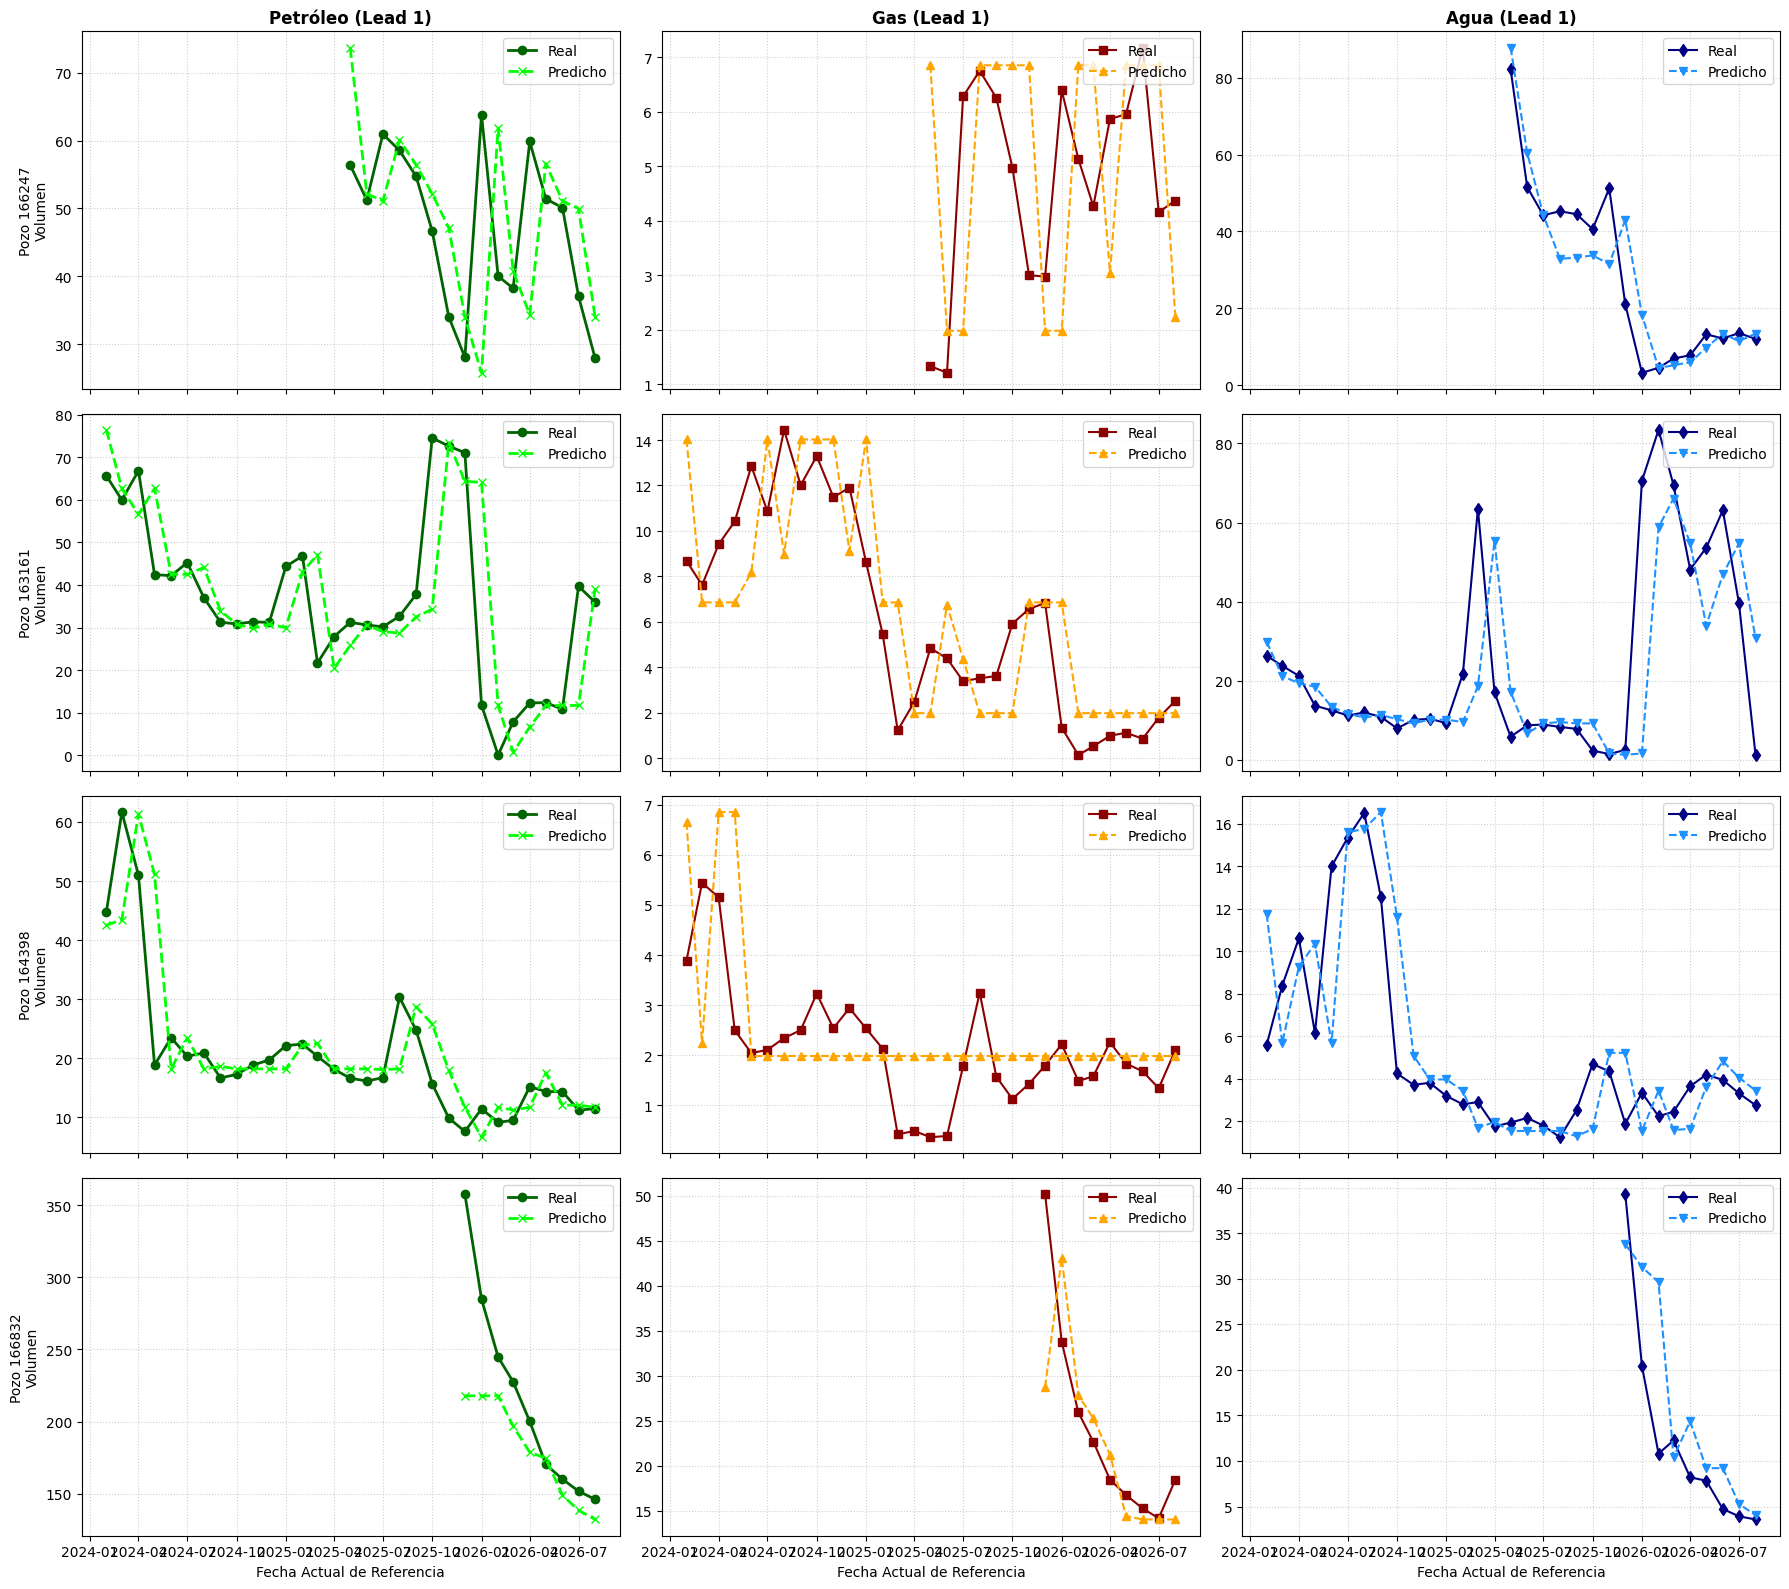

In [13]:
numero_de_pozos = 4
# Recuperamos los datos del segmento de testeo utilizando df (que ya contiene los datos ordenados e idpozo)
df_test_original = df.loc[df_limpio.index[mask_test]].copy()

# Añadimos las predicciones obtenidas para el mes siguiente (lead_1)
df_test_original['pred_pet_dia_lead_1'] = y_pred_final[:, 0]
df_test_original['pred_gas_dia_lead_1'] = y_pred_final[:, 1]
df_test_original['pred_agua_dia_lead_1'] = y_pred_final[:, 2]

# Creamos una columna de fecha de forma segura
df_test_original['fecha'] = pd.to_datetime(
    df_test_original['anio'].astype(str) + '-' + df_test_original['mes'].astype(str) + '-01'
)

# Seleccionamos pozos de forma aleatoria con suficiente historial en testeo para la visualización
pozos_disponibles = df_test_original['idpozo'].value_counts()
pozos_con_historial = pozos_disponibles[pozos_disponibles >= 5].index

# Seleccionamos aleatoriamente los pozos de la muestra
random.seed(42)  # Semilla para reproducibilidad
pozos_seleccionados = random.sample(list(pozos_con_historial), min(numero_de_pozos, len(pozos_con_historial)))

print(f"Pozos seleccionados aleatoriamente para la gráfica: {list(pozos_seleccionados)}")

# Graficar un gráfico por fluido (Petróleo, Gas, Agua) para cada pozo
# Usamos subplots organizados en una grilla de (numero_de_pozos) filas y 3 columnas (una columna por fluido)
fig, axes = plt.subplots(len(pozos_seleccionados), 3, figsize=(18, 4 * len(pozos_seleccionados)), sharex=True)

if len(pozos_seleccionados) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, pozo_id in enumerate(pozos_seleccionados):
    df_pozo = df_test_original[df_test_original['idpozo'] == pozo_id].sort_values('fecha')

    # Columna 1: Petróleo
    ax_pet = axes[i, 0]
    ax_pet.plot(df_pozo['fecha'], df_pozo['prod_pet_dia_lead_1'], marker='o', label='Real', color='darkgreen', linewidth=2)
    ax_pet.plot(df_pozo['fecha'], df_pozo['pred_pet_dia_lead_1'], marker='x', linestyle='--', label='Predicho', color='lime', linewidth=2)
    if i == 0:
        ax_pet.set_title("Petróleo (Lead 1)", fontsize=12, fontweight='bold')
    ax_pet.set_ylabel(f"Pozo {pozo_id}\nVolumen", fontsize=10)
    ax_pet.grid(True, linestyle=':', alpha=0.6)
    ax_pet.legend(loc='upper right')

    # Columna 2: Gas
    ax_gas = axes[i, 1]
    ax_gas.plot(df_pozo['fecha'], df_pozo['prod_gas_dia_lead_1'], marker='s', label='Real', color='darkred', linewidth=1.5)
    ax_gas.plot(df_pozo['fecha'], df_pozo['pred_gas_dia_lead_1'], marker='^', linestyle='--', label='Predicho', color='orange', linewidth=1.5)
    if i == 0:
        ax_gas.set_title("Gas (Lead 1)", fontsize=12, fontweight='bold')
    ax_gas.grid(True, linestyle=':', alpha=0.6)
    ax_gas.legend(loc='upper right')

    # Columna 3: Agua
    ax_agua = axes[i, 2]
    ax_agua.plot(df_pozo['fecha'], df_pozo['prod_agua_dia_lead_1'], marker='d', label='Real', color='navy', linewidth=1.5)
    ax_agua.plot(df_pozo['fecha'], df_pozo['pred_agua_dia_lead_1'], marker='v', linestyle='--', label='Predicho', color='dodgerblue', linewidth=1.5)
    if i == 0:
        ax_agua.set_title("Agua (Lead 1)", fontsize=12, fontweight='bold')
    ax_agua.grid(True, linestyle=':', alpha=0.6)
    ax_agua.legend(loc='upper right')

# Añadir etiqueta común para el eje X al final de cada columna
for col_idx in range(3):
    axes[-1, col_idx].set_xlabel("Fecha Actual de Referencia", fontsize=10)

plt.tight_layout()
plt.show()

In [14]:
# Para este predictor baseline o naive:
# La predicción para el mes siguiente (lead_1) es exactamente el valor observado en el mes actual.

# Obtener las variables del dataset original evitando nulos en los targets y filtrando por el test set
targets_siguiente = ['prod_pet_dia_lead_1', 'prod_gas_dia_lead_1', 'prod_agua_dia_lead_1']
targets_actual = ['prod_pet_dia', 'prod_gas_dia', 'prod_agua_dia']

# Filtrar el dataframe utilizando la máscara del test set para asegurar consistencia
df_test_eval = df.loc[df_limpio.index[mask_test], targets_actual + targets_siguiente].dropna()

print("--- Evaluación del Predictor Naive (Mes Actual como Predicción del Mes Siguiente) en el Test Set ---")

for col_actual, col_siguiente in zip(targets_actual, targets_siguiente):
    # El valor real del mes siguiente
    y_real = df_test_eval[col_siguiente]
    # La predicción (el valor del mes actual)
    y_pred = df_test_eval[col_actual]

    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mae = mean_absolute_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)

    print(f"\nMétricas al usar {col_actual} para predecir {col_siguiente}:")
    print(f"  R² (Coeficiente de Determinación): {r2:.4f}")
    print(f"  RMSE (Error Cuadrático Medio):    {rmse:.4f}")
    print(f"  MAE (Error Absoluto Medio):       {mae:.4f}")

--- Evaluación del Predictor Naive (Mes Actual como Predicción del Mes Siguiente) en el Test Set ---

Métricas al usar prod_pet_dia para predecir prod_pet_dia_lead_1:
  R² (Coeficiente de Determinación): 0.8146
  RMSE (Error Cuadrático Medio):    16.4061
  MAE (Error Absoluto Medio):       7.5303

Métricas al usar prod_gas_dia para predecir prod_gas_dia_lead_1:
  R² (Coeficiente de Determinación): 0.9461
  RMSE (Error Cuadrático Medio):    3.7951
  MAE (Error Absoluto Medio):       1.5603

Métricas al usar prod_agua_dia para predecir prod_agua_dia_lead_1:
  R² (Coeficiente de Determinación): 0.5575
  RMSE (Error Cuadrático Medio):    16.6431
  MAE (Error Absoluto Medio):       6.2854


Para la extracción del gas el modelo naive supera al random tree, en el resto pierde.